In [1]:
# %pip install --user torchvision

In [2]:
import torch
import os 
from torch.utils.data import DataLoader,Dataset
from torchvision import transforms
from PIL import Image

In [3]:
root_dir_path = "./img_align_celeba/img_align_celeba"

In [4]:
class ImageProcessor:

    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        self.all_img_paths = [
            os.path.join(root_dir_path, img)
            for img in os.listdir(root_dir_path)
            if img.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )  
        ]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations:
            img = self.transformations(img)  # <--- Assign back to `img`

        return img

In [5]:
# import zipfile
# import os

# zip_path = "./img_align_celeba.zip"
# extract_dir = "./img_align_celeba"

# # Extract the zip file if it hasn't been extracted yet
# if not os.path.exists(extract_dir):
#     with zipfile.ZipFile(zip_path, 'r') as zip_ref:
#         zip_ref.extractall(extract_dir)

# # Now use the directory path instead of the zip path
# root_dir_path = extract_dir

# for img in os.listdir(root_dir_path):
#     print(os.path.join(root_dir_path, img))

In [6]:
root_dir_path = "./img_align_celeba/img_align_celeba"

transformation = transforms.Compose(
    [
        transforms.CenterCrop(178),  # 178x178
        transforms.Resize(64),  # 64x64
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),  # [-1, 1]
    ]
)

In [7]:
dataset=ImageProcessor(root_dir_path,transformation)
print(f"loaded{len(dataset)} images")

loaded202599 images


In [8]:
dataloader=DataLoader(dataset,batch_size=128,shuffle=True)

# Generate Network

In [9]:
import torch.nn as nn
import torch.optim as optim 
import numpy as np

In [10]:
class Generator(nn.Module):  # Capital 'M' in Module

    def __init__(self, z_dim=100, img_channels=3):
        super(Generator, self).__init__()
        # fully connected layer
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.ReLU(), 
            nn.Linear(256, 512),
            nn.ReLU(),  
            nn.Linear(512, 1024),
            nn.ReLU(),  
            nn.Linear(1024, 64 * 64 * img_channels),
            nn.Tanh(),  # Output range [-1, 1]
        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64)
        return img

# Discrimination Network

In [11]:
class Discriminator(nn.Module):  # Capital 'M' in Module

    def __init__(self, img_channels=3):
        super(Discriminator, self).__init__()
        # fully connected layer
        self.model = nn.Sequential(
            nn.Flatten(), #4D tensor=>10 
            
            nn.Linear(img_channels*64*64,1024),
            nn.LeakyReLU(0.2,inplace=True), 
            
            nn.Linear(1024,512),
            nn.LeakyReLU(0.2,inplace=True),
            
            nn.Linear(512,256),
            nn.LeakyReLU(0.2,inplace=True),
            
            nn.Linear(256, 1),
            nn.Sigmoid(),  # probability of being real/fake
        )

    def forward(self, img):
        return self.model(img)
        

In [12]:
GAN_loss=nn.BCELoss()

generator=Generator()
g_optimizer=optim.Adam(generator.parameters(),lr=0.0002,betas=(0.5,0.999))

discriminator=Discriminator()
d_optimizer=optim.Adam(discriminator.parameters(),lr=0.0002,betas=(0.5,0.999))

In [13]:
#device
import torch
if torch.backends.mps.is_available():
    device=torch.device("mps")
elif torch.cuda.is_available():
    device=torch.device("cuda")
else:
    device=torch.device("cpu")

print(f"device is {device} ")


device is cpu 


In [14]:
generator=generator.to(device)
discriminator=discriminator.to(device)

## Tranning the GAN

In [15]:
def train(generator, discriminator, dataloader, epochs=20):
    for epoch in range(epochs):
        for i, imgs in enumerate(dataloader):
            real_imgs = imgs.to(device)
            batch_size = real_imgs.size(0)

            # Creates real labels & fake imgs labels
            real_labels = torch.ones(batch_size, 1).to(device)  # [1, 1, 1, ...]
            fake_labels = torch.zeros(
                batch_size, 1
            ).to(device)  # [0, 0, 0, ...]

            # --- Train the Discriminator ---
            d_optimizer.zero_grad()

            # Generate fake images from random noise
            z = torch.randn(batch_size, 100).to(device)
            fake_imgs = generator(z)

            real_loss = GAN_loss(discriminator(real_imgs), real_labels)
            fake_loss = GAN_loss(
                discriminator(fake_imgs.detach()), fake_labels
            )

            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()  # Fixed typo (.backend() -> .backward())
            d_optimizer.step()

            # --- Train the Generator ---
            g_optimizer.zero_grad()

            # Generator loss tries to fool the discriminator (target = real_labels)
            g_loss = GAN_loss(
                discriminator(fake_imgs), real_labels
            )  # Fixed typo (discrimintator)

            g_loss.backward()
            g_optimizer.step()

            if i % 50 == 0:
                print(
                    f"Epoch: {epoch + 1}/{epochs} | Batch: {i + 1} | G_loss: {g_loss.item():.4f} | D_loss: {d_loss.item():.4f}"
                )

        # Save generated images at the end of each epoch
        save_generated_images(generator, epoch, device)

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision


def save_generated_images(generator, epoch, device, num_imgs=8):
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()
    grid = torchvision.utils.make_grid(
        generated_imgs, nrow=4, normalize=True
    )
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch + 1}")
    plt.axis("off")
    plt.show()

Epoch: 1/20 | Batch: 1 | G_loss: 0.7102 | D_loss: 0.6955
Epoch: 1/20 | Batch: 51 | G_loss: 1.0064 | D_loss: 0.2928
Epoch: 1/20 | Batch: 101 | G_loss: 1.5941 | D_loss: 0.2262
Epoch: 1/20 | Batch: 151 | G_loss: 0.9028 | D_loss: 0.3279
Epoch: 1/20 | Batch: 201 | G_loss: 0.6554 | D_loss: 0.3721
Epoch: 1/20 | Batch: 251 | G_loss: 2.4480 | D_loss: 0.0887
Epoch: 1/20 | Batch: 301 | G_loss: 3.0028 | D_loss: 0.2821
Epoch: 1/20 | Batch: 351 | G_loss: 2.2299 | D_loss: 0.2556
Epoch: 1/20 | Batch: 401 | G_loss: 2.8428 | D_loss: 0.1308
Epoch: 1/20 | Batch: 451 | G_loss: 2.4375 | D_loss: 0.3206
Epoch: 1/20 | Batch: 501 | G_loss: 0.2709 | D_loss: 0.3614
Epoch: 1/20 | Batch: 551 | G_loss: 2.5689 | D_loss: 0.1501
Epoch: 1/20 | Batch: 601 | G_loss: 0.8192 | D_loss: 0.2765
Epoch: 1/20 | Batch: 651 | G_loss: 0.5681 | D_loss: 0.8770
Epoch: 1/20 | Batch: 701 | G_loss: 0.5819 | D_loss: 0.6010
Epoch: 1/20 | Batch: 751 | G_loss: 2.6462 | D_loss: 0.2372
Epoch: 1/20 | Batch: 801 | G_loss: 2.9212 | D_loss: 0.3520


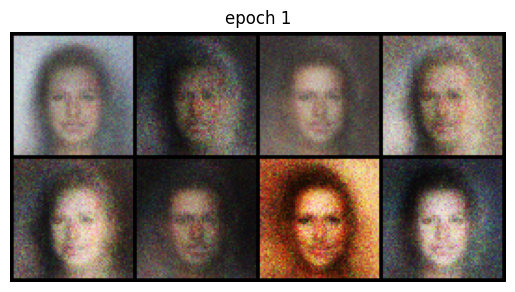

Epoch: 2/20 | Batch: 1 | G_loss: 2.2818 | D_loss: 0.3864
Epoch: 2/20 | Batch: 51 | G_loss: 2.8350 | D_loss: 0.2836
Epoch: 2/20 | Batch: 101 | G_loss: 2.8895 | D_loss: 0.2689
Epoch: 2/20 | Batch: 151 | G_loss: 1.8682 | D_loss: 0.5107
Epoch: 2/20 | Batch: 201 | G_loss: 2.5335 | D_loss: 0.3209
Epoch: 2/20 | Batch: 251 | G_loss: 2.7866 | D_loss: 0.3569
Epoch: 2/20 | Batch: 301 | G_loss: 1.4748 | D_loss: 0.4510
Epoch: 2/20 | Batch: 351 | G_loss: 2.5058 | D_loss: 0.2083
Epoch: 2/20 | Batch: 401 | G_loss: 1.9469 | D_loss: 0.3791
Epoch: 2/20 | Batch: 451 | G_loss: 1.8475 | D_loss: 0.4833
Epoch: 2/20 | Batch: 501 | G_loss: 1.9627 | D_loss: 0.3505
Epoch: 2/20 | Batch: 551 | G_loss: 2.0602 | D_loss: 0.3583
Epoch: 2/20 | Batch: 601 | G_loss: 1.9984 | D_loss: 0.3708
Epoch: 2/20 | Batch: 651 | G_loss: 2.2256 | D_loss: 0.3862
Epoch: 2/20 | Batch: 701 | G_loss: 2.5397 | D_loss: 0.4750
Epoch: 2/20 | Batch: 751 | G_loss: 2.3540 | D_loss: 0.5115
Epoch: 2/20 | Batch: 801 | G_loss: 2.3001 | D_loss: 0.3633


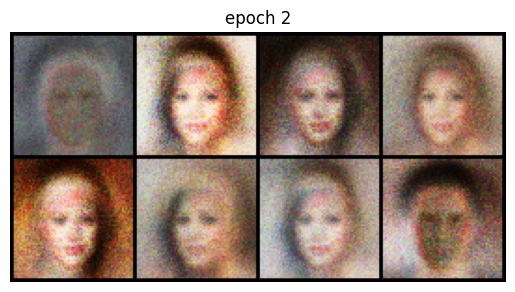

Epoch: 3/20 | Batch: 1 | G_loss: 2.2106 | D_loss: 0.4522
Epoch: 3/20 | Batch: 51 | G_loss: 1.8632 | D_loss: 0.5179
Epoch: 3/20 | Batch: 101 | G_loss: 2.2266 | D_loss: 0.4814
Epoch: 3/20 | Batch: 151 | G_loss: 2.0095 | D_loss: 0.4631
Epoch: 3/20 | Batch: 201 | G_loss: 2.6360 | D_loss: 0.4805
Epoch: 3/20 | Batch: 251 | G_loss: 2.0458 | D_loss: 0.4688
Epoch: 3/20 | Batch: 301 | G_loss: 2.1489 | D_loss: 0.3675
Epoch: 3/20 | Batch: 351 | G_loss: 2.8399 | D_loss: 0.3733
Epoch: 3/20 | Batch: 401 | G_loss: 2.2339 | D_loss: 0.3863
Epoch: 3/20 | Batch: 451 | G_loss: 1.7728 | D_loss: 0.4093
Epoch: 3/20 | Batch: 501 | G_loss: 2.1638 | D_loss: 0.4074
Epoch: 3/20 | Batch: 551 | G_loss: 2.3918 | D_loss: 0.3403
Epoch: 3/20 | Batch: 601 | G_loss: 1.9442 | D_loss: 0.4400
Epoch: 3/20 | Batch: 651 | G_loss: 1.7218 | D_loss: 0.6386
Epoch: 3/20 | Batch: 701 | G_loss: 2.3600 | D_loss: 0.3913
Epoch: 3/20 | Batch: 751 | G_loss: 1.8517 | D_loss: 0.4756
Epoch: 3/20 | Batch: 801 | G_loss: 2.1101 | D_loss: 0.3864


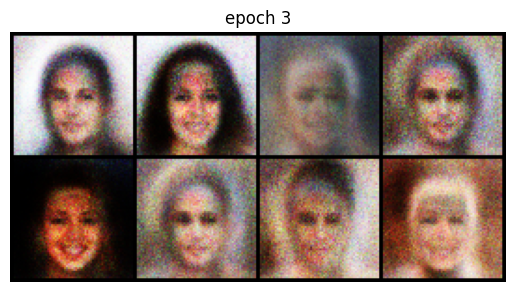

Epoch: 4/20 | Batch: 1 | G_loss: 1.8588 | D_loss: 0.4302
Epoch: 4/20 | Batch: 51 | G_loss: 2.1580 | D_loss: 0.4142
Epoch: 4/20 | Batch: 101 | G_loss: 1.7490 | D_loss: 0.5263
Epoch: 4/20 | Batch: 151 | G_loss: 1.5347 | D_loss: 0.4577
Epoch: 4/20 | Batch: 201 | G_loss: 1.7441 | D_loss: 0.4479
Epoch: 4/20 | Batch: 251 | G_loss: 1.9052 | D_loss: 0.4285
Epoch: 4/20 | Batch: 301 | G_loss: 1.7498 | D_loss: 0.5200
Epoch: 4/20 | Batch: 351 | G_loss: 1.5221 | D_loss: 0.4624
Epoch: 4/20 | Batch: 401 | G_loss: 1.7939 | D_loss: 0.4913
Epoch: 4/20 | Batch: 451 | G_loss: 1.5933 | D_loss: 0.5994
Epoch: 4/20 | Batch: 501 | G_loss: 1.8214 | D_loss: 0.5248
Epoch: 4/20 | Batch: 551 | G_loss: 2.2211 | D_loss: 0.5023
Epoch: 4/20 | Batch: 601 | G_loss: 1.6732 | D_loss: 0.4373
Epoch: 4/20 | Batch: 651 | G_loss: 1.7032 | D_loss: 0.5078
Epoch: 4/20 | Batch: 701 | G_loss: 2.3650 | D_loss: 0.4504
Epoch: 4/20 | Batch: 751 | G_loss: 1.6867 | D_loss: 0.4791
Epoch: 4/20 | Batch: 801 | G_loss: 1.3577 | D_loss: 0.5003


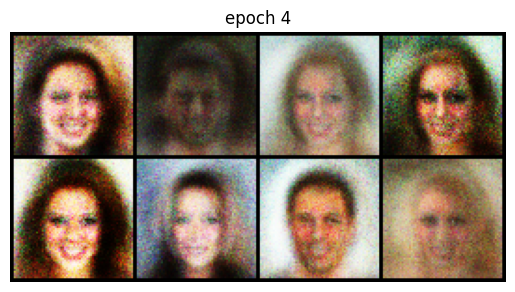

Epoch: 5/20 | Batch: 1 | G_loss: 1.5089 | D_loss: 0.4753
Epoch: 5/20 | Batch: 51 | G_loss: 2.1945 | D_loss: 0.5803
Epoch: 5/20 | Batch: 101 | G_loss: 1.9986 | D_loss: 0.5774
Epoch: 5/20 | Batch: 151 | G_loss: 1.6351 | D_loss: 0.4839
Epoch: 5/20 | Batch: 201 | G_loss: 1.7626 | D_loss: 0.4518
Epoch: 5/20 | Batch: 251 | G_loss: 1.8513 | D_loss: 0.5084
Epoch: 5/20 | Batch: 301 | G_loss: 1.6992 | D_loss: 0.5471
Epoch: 5/20 | Batch: 351 | G_loss: 1.5758 | D_loss: 0.4752
Epoch: 5/20 | Batch: 401 | G_loss: 1.6019 | D_loss: 0.4392
Epoch: 5/20 | Batch: 451 | G_loss: 1.5904 | D_loss: 0.6010
Epoch: 5/20 | Batch: 501 | G_loss: 1.5427 | D_loss: 0.5077
Epoch: 5/20 | Batch: 551 | G_loss: 1.8052 | D_loss: 0.5326
Epoch: 5/20 | Batch: 601 | G_loss: 1.5036 | D_loss: 0.4827
Epoch: 5/20 | Batch: 651 | G_loss: 1.4902 | D_loss: 0.5458
Epoch: 5/20 | Batch: 701 | G_loss: 1.5502 | D_loss: 0.5416
Epoch: 5/20 | Batch: 751 | G_loss: 1.6372 | D_loss: 0.4921
Epoch: 5/20 | Batch: 801 | G_loss: 1.4300 | D_loss: 0.5104


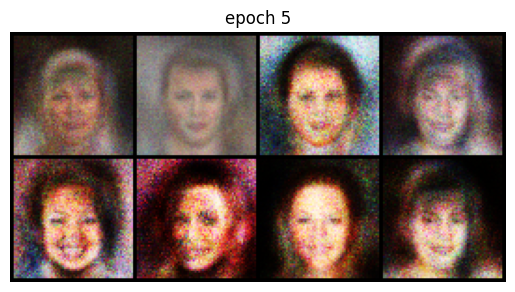

Epoch: 6/20 | Batch: 1 | G_loss: 1.6507 | D_loss: 0.5283
Epoch: 6/20 | Batch: 51 | G_loss: 1.5997 | D_loss: 0.5908
Epoch: 6/20 | Batch: 101 | G_loss: 1.3024 | D_loss: 0.5436
Epoch: 6/20 | Batch: 151 | G_loss: 1.8284 | D_loss: 0.5464
Epoch: 6/20 | Batch: 201 | G_loss: 1.5677 | D_loss: 0.4789
Epoch: 6/20 | Batch: 251 | G_loss: 1.5436 | D_loss: 0.4887
Epoch: 6/20 | Batch: 301 | G_loss: 1.5339 | D_loss: 0.4600
Epoch: 6/20 | Batch: 351 | G_loss: 1.4789 | D_loss: 0.5137
Epoch: 6/20 | Batch: 401 | G_loss: 1.3793 | D_loss: 0.5791
Epoch: 6/20 | Batch: 451 | G_loss: 1.6370 | D_loss: 0.5591
Epoch: 6/20 | Batch: 501 | G_loss: 1.4694 | D_loss: 0.4791
Epoch: 6/20 | Batch: 551 | G_loss: 1.6557 | D_loss: 0.5211
Epoch: 6/20 | Batch: 601 | G_loss: 1.5708 | D_loss: 0.5655
Epoch: 6/20 | Batch: 651 | G_loss: 1.7901 | D_loss: 0.4646
Epoch: 6/20 | Batch: 701 | G_loss: 1.5753 | D_loss: 0.4685
Epoch: 6/20 | Batch: 751 | G_loss: 1.5930 | D_loss: 0.5085
Epoch: 6/20 | Batch: 801 | G_loss: 1.5817 | D_loss: 0.5307


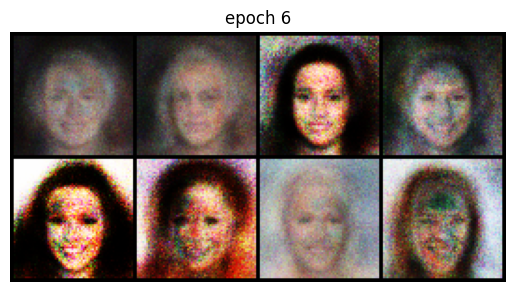

Epoch: 7/20 | Batch: 1 | G_loss: 1.6912 | D_loss: 0.5137
Epoch: 7/20 | Batch: 51 | G_loss: 1.5403 | D_loss: 0.6079
Epoch: 7/20 | Batch: 101 | G_loss: 1.4279 | D_loss: 0.5716
Epoch: 7/20 | Batch: 151 | G_loss: 1.5873 | D_loss: 0.4967
Epoch: 7/20 | Batch: 201 | G_loss: 1.3188 | D_loss: 0.5635
Epoch: 7/20 | Batch: 251 | G_loss: 1.4818 | D_loss: 0.4777
Epoch: 7/20 | Batch: 301 | G_loss: 1.3695 | D_loss: 0.5627
Epoch: 7/20 | Batch: 351 | G_loss: 1.4728 | D_loss: 0.5428
Epoch: 7/20 | Batch: 401 | G_loss: 1.2262 | D_loss: 0.5455
Epoch: 7/20 | Batch: 451 | G_loss: 1.4063 | D_loss: 0.5863
Epoch: 7/20 | Batch: 501 | G_loss: 1.4567 | D_loss: 0.5286
Epoch: 7/20 | Batch: 551 | G_loss: 1.3318 | D_loss: 0.6199
Epoch: 7/20 | Batch: 601 | G_loss: 1.2938 | D_loss: 0.5511
Epoch: 7/20 | Batch: 651 | G_loss: 1.2830 | D_loss: 0.5747
Epoch: 7/20 | Batch: 701 | G_loss: 1.4678 | D_loss: 0.5001
Epoch: 7/20 | Batch: 751 | G_loss: 1.7777 | D_loss: 0.5069
Epoch: 7/20 | Batch: 801 | G_loss: 1.4961 | D_loss: 0.5712


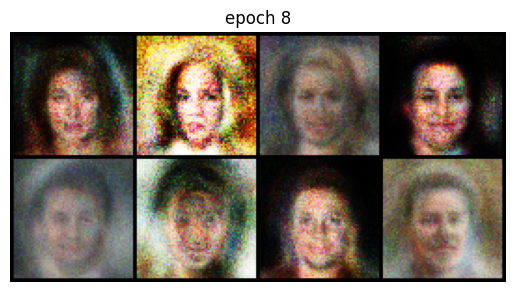

Epoch: 9/20 | Batch: 1 | G_loss: 1.3578 | D_loss: 0.5725
Epoch: 9/20 | Batch: 51 | G_loss: 1.3609 | D_loss: 0.5964
Epoch: 9/20 | Batch: 101 | G_loss: 1.3004 | D_loss: 0.6155
Epoch: 9/20 | Batch: 151 | G_loss: 1.2108 | D_loss: 0.6250
Epoch: 9/20 | Batch: 201 | G_loss: 1.0957 | D_loss: 0.6033
Epoch: 9/20 | Batch: 251 | G_loss: 1.1557 | D_loss: 0.6238
Epoch: 9/20 | Batch: 301 | G_loss: 1.2692 | D_loss: 0.5749
Epoch: 9/20 | Batch: 351 | G_loss: 1.4070 | D_loss: 0.6406
Epoch: 9/20 | Batch: 401 | G_loss: 1.2671 | D_loss: 0.5908
Epoch: 9/20 | Batch: 451 | G_loss: 1.3766 | D_loss: 0.5237
Epoch: 9/20 | Batch: 501 | G_loss: 1.3216 | D_loss: 0.5509
Epoch: 9/20 | Batch: 551 | G_loss: 1.3188 | D_loss: 0.6064
Epoch: 9/20 | Batch: 601 | G_loss: 1.4537 | D_loss: 0.5650
Epoch: 9/20 | Batch: 651 | G_loss: 1.1935 | D_loss: 0.5433
Epoch: 9/20 | Batch: 701 | G_loss: 1.2762 | D_loss: 0.5337
Epoch: 9/20 | Batch: 751 | G_loss: 1.3501 | D_loss: 0.5408
Epoch: 9/20 | Batch: 801 | G_loss: 1.3612 | D_loss: 0.5461


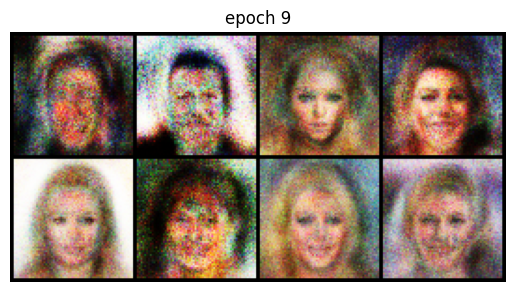

Epoch: 10/20 | Batch: 1 | G_loss: 1.3618 | D_loss: 0.5409
Epoch: 10/20 | Batch: 51 | G_loss: 1.2509 | D_loss: 0.5722
Epoch: 10/20 | Batch: 101 | G_loss: 1.3557 | D_loss: 0.5845
Epoch: 10/20 | Batch: 151 | G_loss: 1.2424 | D_loss: 0.5504
Epoch: 10/20 | Batch: 201 | G_loss: 1.2251 | D_loss: 0.6229
Epoch: 10/20 | Batch: 251 | G_loss: 1.2816 | D_loss: 0.5838
Epoch: 10/20 | Batch: 301 | G_loss: 1.4015 | D_loss: 0.5889
Epoch: 10/20 | Batch: 351 | G_loss: 1.1894 | D_loss: 0.5736
Epoch: 10/20 | Batch: 401 | G_loss: 1.2508 | D_loss: 0.5886
Epoch: 10/20 | Batch: 451 | G_loss: 1.3202 | D_loss: 0.5669
Epoch: 10/20 | Batch: 501 | G_loss: 1.2298 | D_loss: 0.5515
Epoch: 10/20 | Batch: 551 | G_loss: 1.2725 | D_loss: 0.5765
Epoch: 10/20 | Batch: 601 | G_loss: 1.3338 | D_loss: 0.5558
Epoch: 10/20 | Batch: 651 | G_loss: 1.3177 | D_loss: 0.6753
Epoch: 10/20 | Batch: 701 | G_loss: 1.2402 | D_loss: 0.5592
Epoch: 10/20 | Batch: 751 | G_loss: 1.2448 | D_loss: 0.5915
Epoch: 10/20 | Batch: 801 | G_loss: 1.2818 

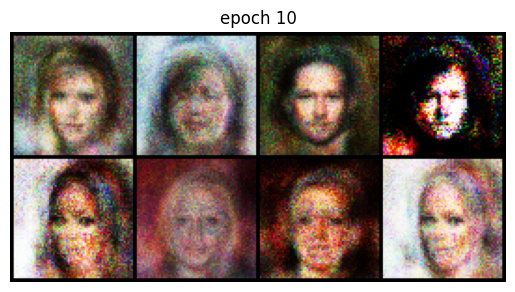

Epoch: 11/20 | Batch: 1 | G_loss: 1.1867 | D_loss: 0.6269


In [ ]:
train(generator,discriminator,dataloader,epochs=20)